# Tema 3 - Laborator 4: Rețele Bayesiene
În această temă folosim rețele bayesiene (biblioteca `pgmpy`) pentru a modela probleme în care unele variabile influențează altele, și facem inferență: calculăm probabilitatea unor variabile neobservate, știind valorile celor observate.

In [1]:
import warnings
warnings.filterwarnings('ignore')   # ascundem avertismentele de tip FutureWarning

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.stats import binom
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

# Seed pentru reproducibilitate
np.random.seed(12)

# Exercițiul 1: Problema Monty Hall
## 1.1. Formularea problemei
La un concurs TV există 3 uși. În spatele uneia se află o mașină, iar în spatele celorlalte două câte o capră.
1. Concurentul alege o ușă (de exemplu ușa 0).
2. Prezentatorul, care **știe** unde este mașina, deschide una dintre celelalte două uși, **întotdeauna una cu capră**.
3. Concurentul este întrebat dacă vrea să rămână la ușa aleasă sau să schimbe pe cealaltă ușă închisă.

Intuitiv pare că rămân două uși, deci șansele sunt 50%–50%. În realitate, **schimbarea ușii dublează șansele de câștig**: de la $1/3$ la $2/3$.

Obiectivul nostru: Să explicăm modelul bayesian din documentația `pgmpy` și să înțelegem de ce schimbarea ușii este mai bună.

## 1.2. Modelul probabilist
Variabilele (fiecare are 3 valori: ușile 0, 1, 2):
- $C$: ușa aleasă de concurent
- $P$: ușa în spatele căreia se află premiul
- $H$: ușa deschisă de prezentator (host)

**Structura rețelei:** $C \rightarrow H \leftarrow P$. Prezentatorul alege ușa în funcție de ușa concurentului **și** de locul premiului, iar $C$ și $P$ sunt independente între ele.

$$P(C, P, H) = P(C) \cdot P(P) \cdot P(H \mid C, P)$$

**Tabelele de probabilități:**
- $P(C = i) = 1/3$: concurentul alege uniform.
- $P(P = i) = 1/3$: premiul este pus uniform.
- $P(H \mid C, P)$ este dat de regulile prezentatorului:
  - nu deschide ușa concurentului;
  - nu deschide ușa cu premiul;
  - dacă $C = P$ (concurentul a ghicit), poate deschide oricare dintre celelalte două uși, cu probabilitatea $1/2$ fiecare;
  - dacă $C \neq P$, rămâne **o singură** ușă posibilă, pe care o deschide cu probabilitatea 1.

In [2]:
# Definim structura: C -> H <- P
model_mh = DiscreteBayesianNetwork([('C', 'H'), ('P', 'H')])

# P(C) și P(P): uniforme pe cele 3 uși
cpd_c = TabularCPD('C', 3, [[1/3], [1/3], [1/3]])
cpd_p = TabularCPD('P', 3, [[1/3], [1/3], [1/3]])

# P(H | C, P): coloanele sunt combinațiile (C, P) în ordinea
# (0,0) (0,1) (0,2) (1,0) (1,1) (1,2) (2,0) (2,1) (2,2)
# rândurile sunt ușa deschisă de prezentator: H = 0, 1, 2
cpd_h = TabularCPD('H', 3,
                   [[0,   0, 0, 0, 0.5, 1, 0, 1, 0.5],
                    [0.5, 0, 1, 0, 0,   0, 1, 0, 0.5],
                    [0.5, 1, 0, 1, 0.5, 0, 0, 0, 0  ]],
                   evidence=['C', 'P'], evidence_card=[3, 3])

model_mh.add_cpds(cpd_c, cpd_p, cpd_h)
print("Modelul este corect definit:", model_mh.check_model())

Modelul este corect definit: True


### Explicații (cum se citește tabelul $P(H \mid C, P)$):
- **Coloana $(C=0, P=0)$**: concurentul a ales ușa cu premiul, deci prezentatorul poate deschide ușa 1 sau 2, fiecare cu 0.5. Coloana este $[0, 0.5, 0.5]$.
- **Coloana $(C=0, P=1)$**: ușa 0 este a concurentului, iar ușa 1 are premiul, deci prezentatorul **trebuie** să deschidă ușa 2. Coloana este $[0, 0, 1]$.
- **Coloana $(C=0, P=2)$**: la fel, trebuie să deschidă ușa 1. Coloana este $[0, 1, 0]$.
- Restul coloanelor se construiesc la fel. Fiecare coloană are suma 1.

În documentația pgmpy probabilitățile uniforme sunt scrise aproximativ ca 0.33; aici am folosit $1/3$, ca suma să fie exact 1.

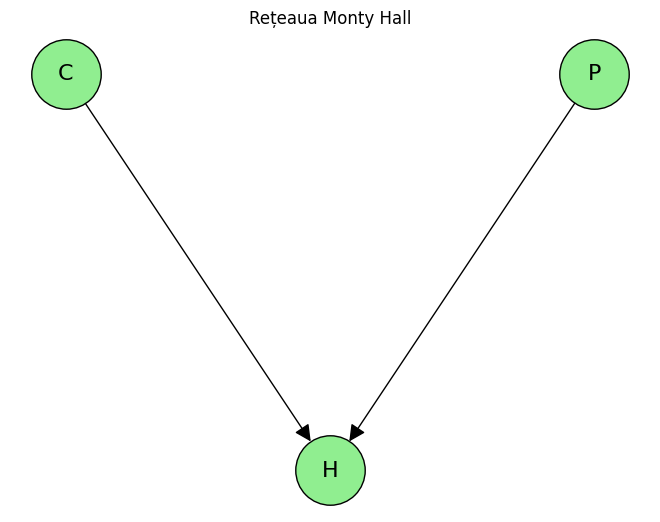

In [3]:
# Desenăm rețeaua
pozitii = {'C': (-1, 1), 'P': (1, 1), 'H': (0, 0)}
nx.draw(model_mh, pozitii, with_labels=True, node_size=2500, node_color='lightgreen',
        edgecolors='black', font_size=16, arrowsize=25)
plt.title('Rețeaua Monty Hall')
plt.show()

## 1.3. Inferența
Concurentul alege ușa 0 ($C = 0$), iar prezentatorul deschide ușa 2 ($H = 2$). Unde este cel mai probabil premiul?

In [4]:
inferenta_mh = VariableElimination(model_mh)
posterior_p = inferenta_mh.query(['P'], evidence={'C': 0, 'H': 2}, show_progress=False)
print(posterior_p)

+------+----------+
| P    |   phi(P) |
+======+==========+
| P(0) |   0.3333 |
+------+----------+
| P(1) |   0.6667 |
+------+----------+
| P(2) |   0.0000 |
+------+----------+


### Calculul manual (regula lui Bayes)
Calculăm $P(P = i \mid C = 0, H = 2)$. Deoarece $C$ și $P$ sunt independente, $P(P = i \mid C = 0) = 1/3$:

$$P(P=i \mid C=0, H=2) = \frac{P(H=2 \mid C=0, P=i)\cdot P(P=i)}{\sum_j P(H=2 \mid C=0, P=j)\cdot P(P=j)}$$

| $P$ | $P(H=2 \mid C=0, P)$ | $\cdot\, P(P)$ | Rezultat |
|---|---|---|---|
| 0 | 0.5 | $0.5 \cdot 1/3 = 1/6$ | $\dfrac{1/6}{1/2} = 1/3$ |
| 1 | 1 | $1 \cdot 1/3 = 1/3$ | $\dfrac{1/3}{1/2} = 2/3$ |
| 2 | 0 | $0$ | $0$ |

Numitorul (formula probabilității totale) este $1/6 + 1/3 + 0 = 1/2$.

### Interpretare:
- Premiul este în spatele ușii alese inițial (0) cu probabilitatea **1/3**.
- Premiul este în spatele celeilalte uși închise (1) cu probabilitatea **2/3**.
- Prin urmare, concurentul **trebuie să schimbe ușa**.

**De ce?** Când concurentul alege, are 1/3 șanse să fi ales corect, iar această probabilitate nu se schimbă. Restul de 2/3 era împărțit între celelalte două uși. Prezentatorul **nu deschide la întâmplare**: el elimină mereu o capră, așa că toată probabilitatea de 2/3 „se mută” pe ușa rămasă închisă.

## 1.4. Verificare prin Simulare
Simulăm 10.000 de jocuri și comparăm cele două strategii: rămânem la ușa inițială sau schimbăm.

In [5]:
N = 10_000
castig_raman = 0
castig_schimb = 0

for _ in range(N):
    premiu = np.random.randint(3)
    alegere = np.random.randint(3)

    # Prezentatorul deschide o ușă care nu e a concurentului și nu are premiul
    posibile = [u for u in range(3) if u != alegere and u != premiu]
    deschisa = np.random.choice(posibile)

    # Ușa la care s-ar schimba concurentul
    alta = [u for u in range(3) if u != alegere and u != deschisa][0]

    castig_raman += (alegere == premiu)
    castig_schimb += (alta == premiu)

print(f"Probabilitatea de câștig dacă rămâne:  {castig_raman / N:.4f}  (teoretic 1/3)")
print(f"Probabilitatea de câștig dacă schimbă: {castig_schimb / N:.4f}  (teoretic 2/3)")

Probabilitatea de câștig dacă rămâne:  0.3442  (teoretic 1/3)
Probabilitatea de câștig dacă schimbă: 0.6558  (teoretic 2/3)


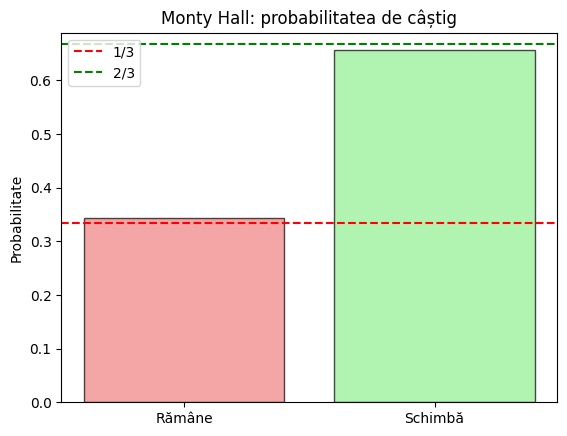

In [6]:
plt.bar(['Rămâne', 'Schimbă'], [castig_raman / N, castig_schimb / N],
        alpha=0.7, color=['lightcoral', 'lightgreen'], edgecolor='black')
plt.axhline(1/3, color='red', linestyle='--', label='1/3')
plt.axhline(2/3, color='green', linestyle='--', label='2/3')
plt.title('Monty Hall: probabilitatea de câștig')
plt.ylabel('Probabilitate')
plt.legend()
plt.show()

# Exercițiul 2: Diagnosticarea Bolii Pulmonare
Un medic vrea să determine probabilitatea ca un pacient să aibă o boală pulmonară, pe baza simptomelor observate. Variabilele (toate binare, 1 = da, 0 = nu):
- $B$: pacientul are boala pulmonară
- $T$: tuse
- $D$: dificultăți de respirație
- $X$: radiografie anormală

Din enunț:
- boala influențează tusea și radiografia: $B \rightarrow T$, $B \rightarrow X$;
- dificultatea de respirație depinde de boală și de tuse: $B \rightarrow D$, $T \rightarrow D$.

Obiectivul nostru: Să definim modelul în pgmpy și să calculăm, știind simptomele, probabilitatea bolii și probabilitatea unei radiografii anormale.

## 2.a. Definirea modelului probabilist
**Descompunerea probabilității comune** (fiecare nod condiționat de părinții lui):
$$P(B, T, X, D) = P(B) \cdot P(T \mid B) \cdot P(X \mid B) \cdot P(D \mid B, T)$$

**Tabelele complete** (valorile pentru 0 se obțin prin complement):

| | $B = 1$ | $B = 0$ |
|---|---|---|
| $P(B)$ | 0.1 | 0.9 |
| $P(T = 1 \mid B)$ | 0.8 | 0.3 |
| $P(T = 0 \mid B)$ | 0.2 | 0.7 |
| $P(X = 1 \mid B)$ | 0.9 | 0.1 |
| $P(X = 0 \mid B)$ | 0.1 | 0.9 |

| | $B=1, T=1$ | $B=1, T=0$ | $B=0, T=1$ | $B=0, T=0$ |
|---|---|---|---|---|
| $P(D = 1 \mid B, T)$ | 0.9 | 0.4 | 0.5 | 0.1 |
| $P(D = 0 \mid B, T)$ | 0.1 | 0.6 | 0.5 | 0.9 |

In [7]:
# Structura rețelei
model = DiscreteBayesianNetwork([('B', 'T'), ('B', 'X'), ('B', 'D'), ('T', 'D')])

# Rândul 0 = valoarea 0, rândul 1 = valoarea 1
cpd_b = TabularCPD('B', 2, [[0.9], [0.1]])

cpd_t = TabularCPD('T', 2, [[0.7, 0.2],     # T = 0, pentru B = 0 și B = 1
                            [0.3, 0.8]],    # T = 1
                   evidence=['B'], evidence_card=[2])

cpd_x = TabularCPD('X', 2, [[0.9, 0.1],
                            [0.1, 0.9]],
                   evidence=['B'], evidence_card=[2])

# Coloanele: (B=0,T=0), (B=0,T=1), (B=1,T=0), (B=1,T=1)
cpd_d = TabularCPD('D', 2, [[0.9, 0.5, 0.6, 0.1],
                            [0.1, 0.5, 0.4, 0.9]],
                   evidence=['B', 'T'], evidence_card=[2, 2])

model.add_cpds(cpd_b, cpd_t, cpd_x, cpd_d)
print("Modelul este corect definit:", model.check_model())

Modelul este corect definit: True


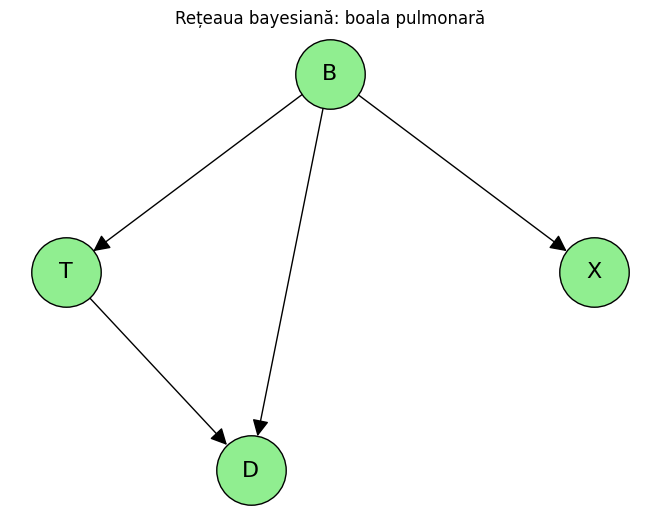

Independențele locale din rețea:
(D ⟂ X | B, T)
(T ⟂ X | B)
(X ⟂ D, T | B)


In [8]:
# Desenăm rețeaua
pozitii = {'B': (0, 1), 'T': (-1, 0), 'X': (1, 0), 'D': (-0.3, -1)}
nx.draw(model, pozitii, with_labels=True, node_size=2500, node_color='lightgreen',
        edgecolors='black', font_size=16, arrowsize=25)
plt.title('Rețeaua bayesiană: boala pulmonară')
plt.show()

print("Independențele locale din rețea:")
print(model.local_independencies(['B', 'T', 'X', 'D']))

### Explicații:
- `TabularCPD('T', 2, ..., evidence=['B'])`: tabelul pentru $T$, care are 2 valori și părintele $B$.
- Pentru `cpd_d`, coloanele urmează ordinea părinților din `evidence=['B', 'T']`: întâi variază $T$, apoi $B$.
- Independențele locale ne arată, de exemplu, că $X \perp \{T, D\} \mid B$: radiografia depinde doar de boală.

## 2.b. Pacientul are tuse și dificultăți de respirație: $P(B = 1 \mid T = 1, D = 1)$

In [9]:
inferenta = VariableElimination(model)

rezultat_b = inferenta.query(['B'], evidence={'T': 1, 'D': 1}, show_progress=False)
print(rezultat_b)
print(f"P(B=1 | T=1, D=1) = {rezultat_b.get_value(B=1):.4f}")

+------+----------+
| B    |   phi(B) |
+======+==========+
| B(0) |   0.6522 |
+------+----------+
| B(1) |   0.3478 |
+------+----------+
P(B=1 | T=1, D=1) = 0.3478


### Interpretare:
Probabilitatea de boală crește de la **10%** (prior) la aproximativ **34.8%**. Tusea și dificultățile de respirație sunt indicii importante, dar nu suficiente: boala este rară, iar aceste simptome apar destul de des și la pacienții sănătoși (de exemplu $P(T=1 \mid B=0) = 0.3$).

## Vizualizarea Actualizării Probabilității (2.b)
Cum se schimbă probabilitatea bolii după ce medicul observă simptomele.

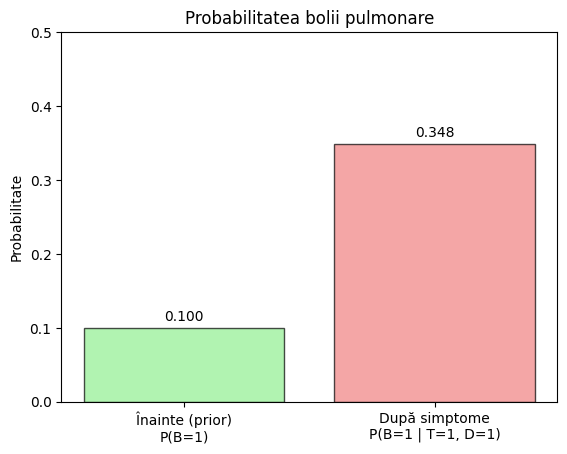

In [10]:
# Comparăm probabilitatea bolii înainte și după observarea simptomelor
etape = ['Înainte (prior)\nP(B=1)', 'După simptome\nP(B=1 | T=1, D=1)']
valori = [0.1, rezultat_b.get_value(B=1)]

plt.bar(etape, valori, alpha=0.7, color=['lightgreen', 'lightcoral'], edgecolor='black')
for i, v in enumerate(valori):
    plt.text(i, v + 0.01, f'{v:.3f}', ha='center')
plt.title('Probabilitatea bolii pulmonare')
plt.ylabel('Probabilitate')
plt.ylim(0, 0.5)
plt.show()

### Interpretare:
Observarea tusei și a dificultăților de respirație crește probabilitatea bolii de aproximativ 3.5 ori (de la 0.1 la 0.348), dar pacientul tot este mai probabil sănătos.

## 2.c. Pacientul nu avea boala: probabilitatea unei radiografii anormale
Știm acum că $B = 0$ (și, din punctul anterior, $T = 1$, $D = 1$). Căutăm $P(X = 1 \mid B = 0, T = 1, D = 1)$.

In [11]:
rezultat_c = inferenta.query(['X'], evidence={'B': 0, 'T': 1, 'D': 1}, show_progress=False)
print(rezultat_c)
print(f"P(X=1 | B=0, T=1, D=1) = {rezultat_c.get_value(X=1):.4f}")

# Comparăm cu P(X=1 | B=0), fără simptome
rezultat_c2 = inferenta.query(['X'], evidence={'B': 0}, show_progress=False)
print(f"P(X=1 | B=0)           = {rezultat_c2.get_value(X=1):.4f}")

+------+----------+
| X    |   phi(X) |
+======+==========+
| X(0) |   0.9000 |
+------+----------+
| X(1) |   0.1000 |
+------+----------+
P(X=1 | B=0, T=1, D=1) = 0.1000
P(X=1 | B=0)           = 0.1000


### Interpretare:
Rezultatul este **0.1**, exact $P(X=1 \mid B=0)$ din tabel. Odată ce știm că pacientul nu are boala, simptomele (tuse, dificultăți de respirație) **nu mai spun nimic** despre radiografie, deoarece $X \perp \{T, D\} \mid B$.

## 2.d. Calculul celor două probabilități cu regula lui Bayes

### 2.d.1. $P(B = 1 \mid T = 1, D = 1)$

**Pasul 1, regula lui Bayes:**
$$P(B=1 \mid T=1, D=1) = \frac{P(B=1, T=1, D=1)}{P(T=1, D=1)}$$

**Pasul 2, eliminăm $X$:** $X$ nu este observată, iar suma peste valorile ei este 1, deci $X$ dispare din calcul:
$$P(B, T, D) = \sum_x P(B)P(T \mid B)P(X = x \mid B)P(D \mid B, T) = P(B)\,P(T \mid B)\,P(D \mid B, T)$$

**Pasul 3, numărătorul ($B = 1$):**
$$P(B=1, T=1, D=1) = P(B=1) \cdot P(T=1 \mid B=1) \cdot P(D=1 \mid B=1, T=1) = 0.1 \cdot 0.8 \cdot 0.9 = 0.072$$

**Pasul 4, cazul $B = 0$:**
$$P(B=0, T=1, D=1) = 0.9 \cdot 0.3 \cdot 0.5 = 0.135$$

**Pasul 5, numitorul (formula probabilității totale):**
$$P(T=1, D=1) = 0.072 + 0.135 = 0.207$$

**Pasul 6, rezultatul:**
$$P(B=1 \mid T=1, D=1) = \frac{0.072}{0.207} \approx 0.3478$$

### 2.d.2. $P(X = 1 \mid B = 0, T = 1, D = 1)$

**Pasul 1, definiția probabilității condiționate:**
$$P(X=1 \mid B=0, T=1, D=1) = \frac{P(B=0, T=1, X=1, D=1)}{P(B=0, T=1, D=1)}$$

**Pasul 2, descompunerea după rețea:**
$$= \frac{P(B=0)\,P(T=1 \mid B=0)\,P(X=1 \mid B=0)\,P(D=1 \mid B=0, T=1)}{P(B=0)\,P(T=1 \mid B=0)\,P(D=1 \mid B=0, T=1)}$$

**Pasul 3, simplificăm** (termenii comuni se reduc):
$$= P(X=1 \mid B=0) = 0.1$$

Altfel spus, folosim independența condiționată din rețea, $X \perp \{T, D\} \mid B$: știind $B$, simptomele nu mai influențează radiografia.

Numeric: $\dfrac{0.9 \cdot 0.3 \cdot 0.1 \cdot 0.5}{0.9 \cdot 0.3 \cdot 0.5} = \dfrac{0.0135}{0.135} = 0.1$.

In [12]:
# Verificăm calculul manual
num = 0.1 * 0.8 * 0.9
caz_b0 = 0.9 * 0.3 * 0.5
print(f"\nValoarea calculată manual pentru 2.b: {num / (num + caz_b0):.4f}")
print(f"Valoarea obținută cu pgmpy pentru 2.b: {rezultat_b.get_value(B=1):.4f}")
print(f"\nValoarea calculată manual pentru 2.c: {(0.9*0.3*0.1*0.5) / (0.9*0.3*0.5):.4f}")
print(f"Valoarea obținută cu pgmpy pentru 2.c: {rezultat_c.get_value(X=1):.4f}")


Valoarea calculată manual pentru 2.b: 0.3478
Valoarea obținută cu pgmpy pentru 2.b: 0.3478

Valoarea calculată manual pentru 2.c: 0.1000
Valoarea obținută cu pgmpy pentru 2.c: 0.1000


# Exercițiul 3: Jocul cu Moneda și Zarul
Doi jucători, $J_0$ și $J_1$, joacă astfel:
1. Se aruncă o monedă **normală** pentru a decide cine începe.
2. **Runda 1:** jucătorul care începe aruncă zarul; fie $n$ numărul obținut.
3. **Runda 2:** celălalt jucător aruncă **propria monedă** de $2n$ ori; fie $m$ numărul de steme.

Jucătorul din prima rundă câștigă dacă $n \geq m$, altfel câștigă cel din runda a doua.

$J_1$ este necinstit: moneda lui dă stemă cu probabilitatea $4/7$. Moneda lui $J_0$ este normală (1/2), iar zarurile sunt normale.

Obiectivul nostru: Să estimăm cine are șanse mai mari de câștig, să modelăm jocul cu o rețea bayesiană și să aflăm cine a început cel mai probabil, știind că în runda a doua s-a obținut o singură stemă.

## 3.a. Estimarea șanselor de câștig (10.000 de jocuri)

In [13]:
p_stema = {0: 1/2, 1: 4/7}    # probabilitatea de stemă pentru moneda lui J0 și J1

def joc():
    primul = np.random.randint(2)          # 0 = J0 începe, 1 = J1 începe
    al_doilea = 1 - primul

    n = np.random.randint(1, 7)            # runda 1: zarul
    m = np.random.binomial(2 * n, p_stema[al_doilea])   # runda 2: 2n aruncări cu moneda proprie

    castigator = primul if n >= m else al_doilea
    return castigator

N = 10_000
castigatori = np.array([joc() for _ in range(N)])

p_J0 = np.mean(castigatori == 0)
p_J1 = np.mean(castigatori == 1)
print(f"J0 câștigă în {p_J0:.4f} din jocuri")
print(f"J1 câștigă în {p_J1:.4f} din jocuri")

J0 câștigă în 0.4280 din jocuri
J1 câștigă în 0.5720 din jocuri


### Explicații:
- `np.random.randint(2)`: moneda normală care decide cine începe.
- `np.random.randint(1, 7)`: zarul din runda 1.
- `np.random.binomial(2 * n, p)`: numărul de steme din $2n$ aruncări ale unei monede cu probabilitatea de stemă $p$ (distribuția binomială).
- Jucătorul din runda a doua folosește **propria monedă**: dacă începe $J_0$, aruncă $J_1$ (cu $p = 4/7$), și invers.

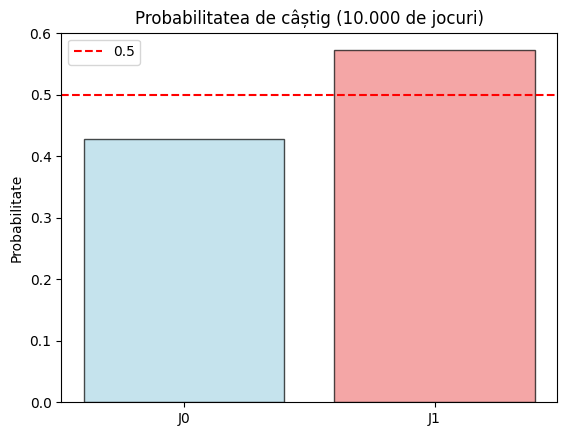

In [14]:
plt.bar(['J0', 'J1'], [p_J0, p_J1], alpha=0.7, color=['lightblue', 'lightcoral'], edgecolor='black')
plt.axhline(0.5, color='red', linestyle='--', label='0.5')
plt.title('Probabilitatea de câștig (10.000 de jocuri)')
plt.ylabel('Probabilitate')
plt.legend()
plt.show()

### Interpretare:
**$J_1$ are șanse mai mari de câștig** (aproximativ 57%, față de 43% pentru $J_0$).

De ce: când $J_1$ este în runda a doua, moneda lui măsluită (4/7) produce mai multe steme, deci $m$ este mai des mai mare decât $n$. Când $J_0$ este în runda a doua, moneda lui normală produce mai puține steme, deci $J_1$ (care a aruncat zarul) câștigă mai des.

Valoarea exactă, calculată cu formula probabilității totale după cine începe și ce dă zarul:
$$P(J_0 \text{ câștigă}) = \tfrac{1}{2}\sum_{n=1}^{6}\tfrac{1}{6}P(m \le n \mid 2n, \tfrac{4}{7}) + \tfrac{1}{2}\sum_{n=1}^{6}\tfrac{1}{6}P(m > n \mid 2n, \tfrac{1}{2}) \approx 0.427$$

In [15]:
# Valoarea exactă, pentru comparație
p0_incepe = sum(1/6 * binom.cdf(n, 2*n, 4/7) for n in range(1, 7))        # J0 începe și câștigă
p0_al_doilea = sum(1/6 * (1 - binom.cdf(n, 2*n, 1/2)) for n in range(1, 7))  # J1 începe, J0 câștigă
p_J0_exact = 0.5 * p0_incepe + 0.5 * p0_al_doilea

print(f"Valoarea exactă pentru J0:   {p_J0_exact:.4f}")
print(f"Valoarea estimată pentru J0: {p_J0:.4f}")
print(f"\nValoarea exactă pentru J1:   {1 - p_J0_exact:.4f}")
print(f"Valoarea estimată pentru J1: {p_J1:.4f}")

Valoarea exactă pentru J0:   0.4267
Valoarea estimată pentru J0: 0.4280

Valoarea exactă pentru J1:   0.5733
Valoarea estimată pentru J1: 0.5720


## Vizualizarea Datelor (3.a)
Distribuția numărului de steme $M$ din runda a doua, separat după moneda folosită.

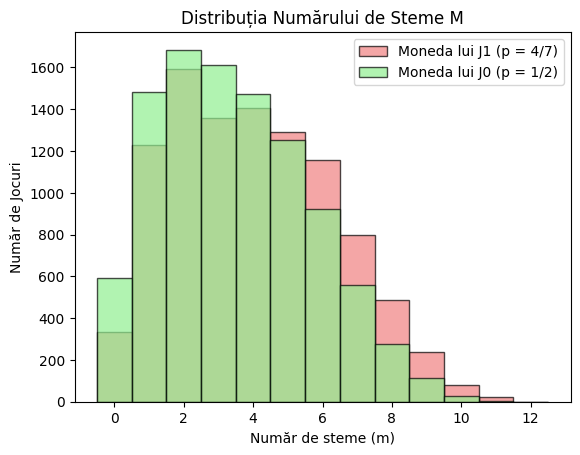

In [16]:
# Simulăm numărul de steme din runda a doua, separat pentru cele două monede
m_J1 = [np.random.binomial(2 * np.random.randint(1, 7), 4/7) for _ in range(N)]   # aruncă J1 (începe J0)
m_J0 = [np.random.binomial(2 * np.random.randint(1, 7), 1/2) for _ in range(N)]   # aruncă J0 (începe J1)

bins = np.arange(-0.5, 13.5, 1)
plt.hist(m_J1, bins=bins, alpha=0.7, color='lightcoral', edgecolor='black', label='Moneda lui J1 (p = 4/7)')
plt.hist(m_J0, bins=bins, alpha=0.7, color='lightgreen', edgecolor='black', label='Moneda lui J0 (p = 1/2)')
plt.title('Distribuția Numărului de Steme M')
plt.xlabel('Număr de steme (m)')
plt.ylabel('Număr de Jocuri')
plt.legend()
plt.show()

### Interpretare:
Cu moneda măsluită a lui $J_1$, distribuția lui $M$ este deplasată spre dreapta (mai multe steme), deci $m$ depășește mai des pe $n$. Cu moneda normală a lui $J_0$, valorile mici (de exemplu $m = 1$) sunt mai frecvente, ceea ce explică și rezultatul de la 3.c.

## 3.b. Rețeaua bayesiană
Variabilele:
- $S$: cine începe (0 = $J_0$, 1 = $J_1$), cu $P(S = 0) = P(S = 1) = 1/2$
- $N$: rezultatul zarului din runda 1, $N \in \{1, \dots, 6\}$, cu probabilitatea $1/6$ fiecare
- $M$: numărul de steme din runda a doua, $M \in \{0, \dots, 12\}$
- $W$: câștigătorul (0 = $J_0$, 1 = $J_1$)

**Structura:**
- $N$ nu depinde de $S$ (ambele zaruri sunt normale);
- $M$ depinde de $N$ (numărul de aruncări este $2N$) și de $S$ (dă moneda folosită): $S \rightarrow M$, $N \rightarrow M$;
- $W$ depinde de $S$, $N$ și $M$: $S \rightarrow W$, $N \rightarrow W$, $M \rightarrow W$.

**Tabelul pentru $M$** este distribuția binomială:
$$P(M = m \mid S, N = n) = \binom{2n}{m} p^m (1-p)^{2n-m}, \quad p = \begin{cases} 4/7 & \text{dacă } S = 0 \text{ (aruncă } J_1) \\ 1/2 & \text{dacă } S = 1 \text{ (aruncă } J_0) \end{cases}$$

**Tabelul pentru $W$** este determinist: câștigă cel care a început dacă $N \geq M$, altfel celălalt.

In [17]:
model_joc = DiscreteBayesianNetwork([('S', 'M'), ('N', 'M'), ('S', 'W'), ('N', 'W'), ('M', 'W')])

valori_N = [1, 2, 3, 4, 5, 6]
valori_M = list(range(13))   # 0 ... 12 steme

cpd_s = TabularCPD('S', 2, [[0.5], [0.5]], state_names={'S': [0, 1]})
cpd_n = TabularCPD('N', 6, [[1/6]] * 6, state_names={'N': valori_N})

# P(M | S, N): coloanele sunt (S=0,N=1) ... (S=0,N=6), (S=1,N=1) ... (S=1,N=6)
coloane_m = []
for s in [0, 1]:
    p = 4/7 if s == 0 else 1/2          # dacă începe J0, aruncă moneda lui J1
    for n in valori_N:
        coloane_m.append([binom.pmf(m, 2 * n, p) for m in valori_M])
cpd_m = TabularCPD('M', 13, np.array(coloane_m).T,
                   evidence=['S', 'N'], evidence_card=[2, 6],
                   state_names={'M': valori_M, 'S': [0, 1], 'N': valori_N})

# P(W | S, N, M): determinist
coloane_w = []
for s in [0, 1]:
    for n in valori_N:
        for m in valori_M:
            castigator = s if n >= m else 1 - s
            coloane_w.append([1 if castigator == 0 else 0, 1 if castigator == 1 else 0])
cpd_w = TabularCPD('W', 2, np.array(coloane_w).T,
                   evidence=['S', 'N', 'M'], evidence_card=[2, 6, 13],
                   state_names={'W': [0, 1], 'S': [0, 1], 'N': valori_N, 'M': valori_M})

model_joc.add_cpds(cpd_s, cpd_n, cpd_m, cpd_w)
print("Modelul este corect definit:", model_joc.check_model())

Modelul este corect definit: True


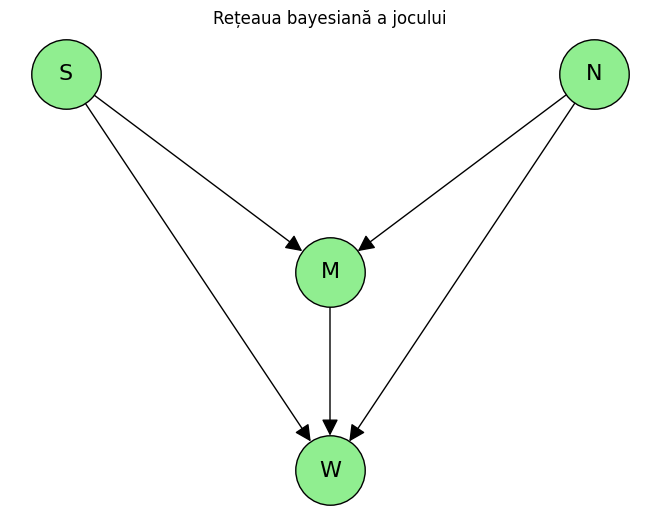

+------+----------+
| W    |   phi(W) |
+======+==========+
| W(0) |   0.4267 |
+------+----------+
| W(1) |   0.5733 |
+------+----------+


In [18]:
# Desenăm rețeaua
pozitii = {'S': (-1, 1), 'N': (1, 1), 'M': (0, 0), 'W': (0, -1)}
nx.draw(model_joc, pozitii, with_labels=True, node_size=2500, node_color='lightgreen',
        edgecolors='black', font_size=16, arrowsize=25)
plt.title('Rețeaua bayesiană a jocului')
plt.show()

# Verificăm 3.a cu rețeaua: P(W)
inferenta_joc = VariableElimination(model_joc)
print(inferenta_joc.query(['W'], show_progress=False))

### Explicații:
- `binom.pmf(m, 2*n, p)`: probabilitatea de a obține exact $m$ steme din $2n$ aruncări (distribuția binomială). Pentru $m > 2n$ este 0.
- `state_names`: dăm valorile reale ale variabilelor (de exemplu zarul are valorile 1–6, nu 0–5).
- Tabelul lui $W$ conține doar 0 și 1, pentru că, știind $S$, $N$ și $M$, câștigătorul este sigur.
- `query(['W'])` dă aceleași probabilități ca simularea de la 3.a ($J_1 \approx 0.573$).

## 3.c. Cine a început cel mai probabil, știind că în runda a doua s-a obținut o singură stemă?
Căutăm $P(S \mid M = 1)$.

In [19]:
rezultat_3c = inferenta_joc.query(['S'], evidence={'M': 1}, show_progress=False)
print(rezultat_3c)
print(f"P(J0 a început | M=1) = {rezultat_3c.get_value(S=0):.4f}")
print(f"P(J1 a început | M=1) = {rezultat_3c.get_value(S=1):.4f}")

+------+----------+
| S    |   phi(S) |
+======+==========+
| S(0) |   0.4529 |
+------+----------+
| S(1) |   0.5471 |
+------+----------+
P(J0 a început | M=1) = 0.4529
P(J1 a început | M=1) = 0.5471


### Calculul manual (regula lui Bayes)
**Pasul 1, regula lui Bayes:**
$$P(S = s \mid M = 1) = \frac{P(M = 1 \mid S = s)\,P(S = s)}{P(M = 1)}$$

**Pasul 2, formula probabilității totale după zar:**
$$P(M=1 \mid S=s) = \sum_{n=1}^{6} \frac{1}{6} \binom{2n}{1} p\,(1-p)^{2n-1} = \sum_{n=1}^{6} \frac{1}{6} \cdot 2n \cdot p\,(1-p)^{2n-1}$$

| $n$ | $2n \cdot \frac{4}{7}\left(\frac{3}{7}\right)^{2n-1}$ ($S = 0$, aruncă $J_1$) | $2n \cdot \left(\frac{1}{2}\right)^{2n}$ ($S = 1$, aruncă $J_0$) |
|---|---|---|
| 1 | 0.4898 | 0.5000 |
| 2 | 0.1799 | 0.2500 |
| 3 | 0.0496 | 0.0938 |
| 4 | 0.0121 | 0.0313 |
| 5 | 0.0028 | 0.0098 |
| 6 | 0.0006 | 0.0029 |
| **Suma / 6** | **0.1225** | **0.1479** |

**Pasul 3, înlocuim** ($P(S=0) = P(S=1) = 1/2$, se simplifică):
$$P(S=0 \mid M=1) = \frac{0.1225}{0.1225 + 0.1479} \approx 0.453, \qquad P(S=1 \mid M=1) = \frac{0.1479}{0.2704} \approx 0.547$$

### Interpretare:
**Cel mai probabil a început $J_1$** (aproximativ 54.7%).

O singură stemă este un rezultat „mic”. Ea este mai probabilă cu moneda normală a lui $J_0$ (care dă mai puține steme) decât cu moneda măsluită a lui $J_1$ (care dă mai multe). Dacă în runda a doua a aruncat $J_0$, atunci $J_1$ a fost cel care a început jocul.

In [20]:
# Verificăm calculul manual
m1_s0 = sum(1/6 * binom.pmf(1, 2*n, 4/7) for n in range(1, 7))
m1_s1 = sum(1/6 * binom.pmf(1, 2*n, 1/2) for n in range(1, 7))
print(f"P(M=1 | J0 începe) = {m1_s0:.4f}")
print(f"P(M=1 | J1 începe) = {m1_s1:.4f}")
print(f"\nValoarea calculată manual: P(J1 a început | M=1) = {m1_s1 / (m1_s0 + m1_s1):.4f}")
print(f"Valoarea obținută cu pgmpy: P(J1 a început | M=1) = {rezultat_3c.get_value(S=1):.4f}")

P(M=1 | J0 începe) = 0.1225
P(M=1 | J1 începe) = 0.1479

Valoarea calculată manual: P(J1 a început | M=1) = 0.5471
Valoarea obținută cu pgmpy: P(J1 a început | M=1) = 0.5471


## Vizualizarea Rezultatului (3.c)

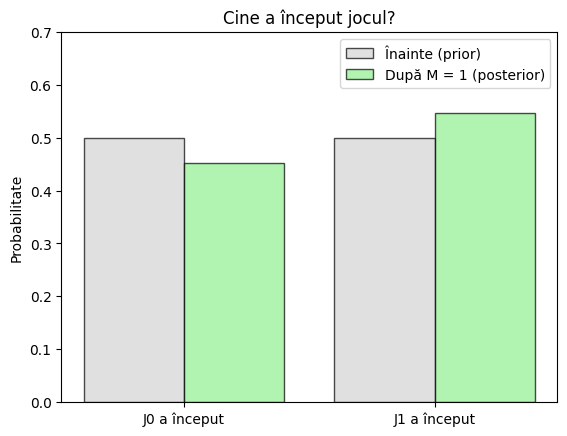

In [21]:
# Comparăm probabilitatea ca fiecare jucător să fi început: înainte și după observația M = 1
x = np.arange(2)
plt.bar(x - 0.2, [0.5, 0.5], width=0.4, alpha=0.7, color='lightgray', edgecolor='black', label='Înainte (prior)')
plt.bar(x + 0.2, [rezultat_3c.get_value(S=0), rezultat_3c.get_value(S=1)], width=0.4,
        alpha=0.7, color='lightgreen', edgecolor='black', label='După M = 1 (posterior)')
plt.xticks(x, ['J0 a început', 'J1 a început'])
plt.title('Cine a început jocul?')
plt.ylabel('Probabilitate')
plt.ylim(0, 0.7)
plt.legend()
plt.show()

### Interpretare:
Înainte de observație, fiecare jucător avea 50% șanse să fi început. După ce aflăm că s-a obținut o singură stemă, probabilitatea se mută spre $J_1$ (54.7%).